In [ ]:
"""%pip install osmnx 
%pip install networkx 
%pip install matplotlib"""


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


Phase 1: Loading the environment, library and graph 

In [6]:
# Cell 1: Imports and setup
import osmnx as ox
import networkx as netx
import matplotlib.pyplot as plt

# Configure OSMnx settings for optimal performance (Updated for newer OSMnx versions)
ox.settings.use_cache = True
ox.settings.log_console = True

print("Libraries imported successfully!")
print(f"OSMnx version: {ox.__version__}")
print(f"NetworkX version: {netx.__version__}")

Libraries imported successfully!
OSMnx version: 2.0.7
NetworkX version: 3.4.2


In [9]:
# Cell 2 (Alternative A): Query the city of Waterloo
place_name = "Waterloo, Ontario, Canada"
G_toy = ox.graph_from_place(place_name, network_type="drive")

print(f"Graph successfully downloaded!")
print(f"Number of nodes (intersections): {len(G_toy.nodes)}")
print(f"Number of edges (directed street segments): {len(G_toy.edges)}")
print(f"Graph type: {type(G_toy)}")

Graph successfully downloaded!
Number of nodes (intersections): 2435
Number of edges (directed street segments): 6541
Graph type: <class 'networkx.classes.multidigraph.MultiDiGraph'>


In [10]:
# Cell 3: Inspecting a sample node and edge
# Get the first node ID in the graph
sample_node_id = list(G_toy.nodes)[0]
sample_node_data = G_toy.nodes[sample_node_id]

print(f"Sample Node ID: {sample_node_id}")
print(f"Node Attributes (Latitude, Longitude, etc.): {sample_node_data}\n")

# Get the first edge in the graph (u, v, key)
sample_edge = list(G_toy.edges)[0]
u, v, key = sample_edge
sample_edge_data = G_toy.get_edge_data(u, v, key)

print(f"Sample Edge from Node {u} to Node {v} (Key: {key})")
print(f"Edge Attributes (Length, Name, MaxSpeed, etc.): {sample_edge_data}")

Sample Node ID: 10782939
Node Attributes (Latitude, Longitude, etc.): {'y': 43.4704584, 'x': -80.5581321, 'highway': 'traffic_signals', 'street_count': 4}

Sample Edge from Node 10782939 to Node 340086040 (Key: 0)
Edge Attributes (Length, Name, MaxSpeed, etc.): {'osmid': 1411375958, 'highway': 'secondary', 'lanes': '3', 'maxspeed': '60', 'name': 'Columbia Street West', 'oneway': True, 'reversed': False, 'length': 11.415096518451344}


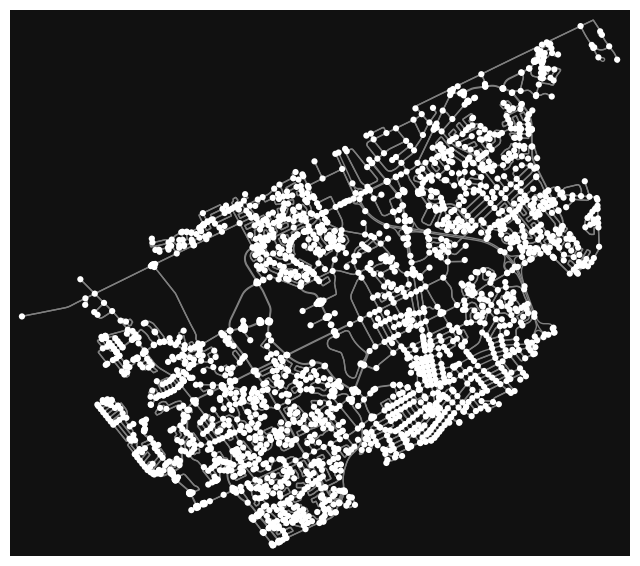

In [11]:
# Cell 4: Plotting the toy graph
fig, ax = ox.plot_graph(G_toy, node_size=20, edge_color="gray", edge_linewidth=1)

Phase 2: Djikstra vs A* Search

I. Djikstra's Algorithm

In [12]:
# Playground 2.1: Comparing Dijkstra vs A* Node Expansion on our Toy Graph
import networkx as nx
import osmnx as ox
import heapq

# Let's use our toy graph from Phase 1 (G_toy or a small subgraph)
# Pick two sample nodes from our toy graph
nodes = list(G_toy.nodes)
source_node = nodes[0]
target_node = nodes[len(nodes) // 2] # Pick a node somewhere across the toy graph

print(f"Source Node: {source_node}")
print(f"Target Node: {target_node}")

# 1. Standard Dijkstra Implementation with Exploration Counter
def custom_dijkstra(G, source, target):
    pq = [(0, source)]
    distances = {source: 0}
    explored_nodes = set()
    parent = {source: None}
    
    while pq:
        current_dist, u = heapq.heappop(pq)
        
        if u in explored_nodes:
            continue
        explored_nodes.add(u)
        
        if u == target:
            break
            
        for v in G.neighbors(u):
            # Get edge weight (travel time or length)
            edge_data = G.get_edge_data(u, v)
            # Take the minimum weight among parallel edges if MultiDiGraph
            weight = min([d.get('length', 1) for d in edge_data.values()])
            
            old_dist = distances.get(v, float('inf'))
            new_dist = current_dist + weight
            
            if new_dist < old_dist:
                distances[v] = new_dist
                parent[v] = u
                heapq.heappush(pq, (new_dist, v))
                
    return explored_nodes

# Run and measure explored nodes
dijkstra_explored = custom_dijkstra(G_toy, source_node, target_node)
print(f"Dijkstra explored {len(dijkstra_explored)} nodes to find the target.")

Source Node: 10782939
Target Node: 340433347
Dijkstra explored 2063 nodes to find the target.


II. A* Search

In [13]:
# Playground 2.1 (Continued): A* Search Implementation with Haversine Heuristic
import math

# Helper function to calculate Haversine distance between two nodes
def haversine_heuristic(u, v, G):
    lat1, lon1 = G.nodes[u]['y'], G.nodes[u]['x']
    lat2, lon2 = G.nodes[v]['y'], G.nodes[v]['x']
    
    # Haversine formula approximation in meters
    R = 6371000  # Earth radius in meters
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    dphi = math.radians(lat2 - lat1)
    dlambda = math.radians(lon2 - lon1)
    
    a = math.sin(dphi/2)**2 + math.cos(phi1) * math.cos(phi2) * math.sin(dlambda/2)**2
    c = 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))
    
    return R * c

def custom_astar(G, source, target):
    # Priority queue stores: (f_score, current_node)
    # f(n) = g(n) + h(n)
    h_init = haversine_heuristic(source, target, G)
    pq = [(h_init, 0, source)]
    
    g_scores = {source: 0}
    explored_nodes = set()
    parent = {source: None}
    
    while pq:
        f, current_g, u = heapq.heappop(pq)
        
        if u in explored_nodes:
            continue
        explored_nodes.add(u)
        
        if u == target:
            break
            
        for v in G.neighbors(u):
            edge_data = G.get_edge_data(u, v)
            weight = min([d.get('length', 1) for d in edge_data.values()])
            
            new_g = current_g + weight
            old_g = g_scores.get(v, float('inf'))
            
            if new_g < old_g:
                g_scores[v] = new_g
                parent[v] = u
                # h(v) estimates remaining distance to target
                h = haversine_heuristic(v, target, G)
                f_v = new_g + h
                heapq.heappush(pq, (f_v, new_g, v))
                
    return explored_nodes

# Run A* and compare explored nodes
astar_explored = custom_astar(G_toy, source_node, target_node)
print(f"A* explored {len(astar_explored)} nodes to find the target.")
print(f"Reduction in search space: {((len(dijkstra_explored) - len(astar_explored)) / len(dijkstra_explored)) * 100:.1f}% fewer nodes explored!")

A* explored 422 nodes to find the target.
Reduction in search space: 79.5% fewer nodes explored!
